# Лабораторная работа 3. Анализ сетевого трафика

## 40 Вариант

**Выполнили** Ниязов Никита Алексеевич и Зверев Егор Дмитриевич

**Группа:** ИНБб-4301-02-00

## Шаг 0. Подключение датасета

Блокнот рассчитан на два варианта запуска (как в ЛР № 2):

- **Google Colab** — раскомментируйте ниже вариант А (датасет на Google Диске) или вариант Б (разовая загрузка в сессию);
- **локальный Jupyter** — просто положите папку `datasets/` рядом с блокнотом и переходите к следующей ячейке.

In [1]:

# Вариант А: архив datasets.zip лежит в корне Google Диска (рекомендуется)
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/

Mounted at /content/drive


In [34]:
import os

# Где лежат данные: рядом с блокнотом (локально) или в /content (Colab)
DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Датасеты на месте:', sorted(os.listdir(DATA_DIR)))

Датасеты на месте: ['KDDTest+.csv', 'KDDTrain+.csv', 'ids.csv']


### Импорты

Все библиотеки стандартны: в Colab они предустановлены, для локального Python при необходимости выполните `!pip install pandas scikit-learn matplotlib`.

In [3]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 2  # фиксируем, чтобы результаты воспроизводились

## Шаг 1. Датасет NSL-KDD

**NSL-KDD** — классический учебный датасет для задач обнаружения сетевых вторжений, улучшенная версия KDD Cup 1999 (подробности — в методичке, Приложение А). Каждая строка — одно **сетевое соединение**, описанное 41 признаком: длительность, протокол, сервис, число байт в обе стороны, различные счётчики и доли ошибок. Последний столбец — метка.

Файл `ids.csv` — компактное подмножество NSL-KDD (~25 тыс. соединений), в котором все типы атак объединены в один класс `anomaly`. Получается **задача бинарной классификации**: `normal` (нормальный трафик) или `anomaly` (атака).

In [4]:
df = pd.read_csv(os.path.join(DATA_DIR, 'ids.csv'))
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (25192, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [5]:
# Пропуски и типы данных
print('Пропущенных значений:', df.isnull().sum().sum())
print()
print(df.dtypes.value_counts().to_frame('число столбцов'))

Пропущенных значений: 0

         число столбцов
int64                23
float64              15
object                4


In [6]:
# Столбцы с единственным значением бесполезны для классификации
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
print('Константные признаки:', const_cols)

df = df.drop(columns=const_cols)
print('Осталось столбцов:', df.shape[1])

Константные признаки: ['num_outbound_cmds', 'is_host_login']
Осталось столбцов: 40


class
normal     13449
anomaly    11743
Name: count, dtype: int64

Доли: normal 53.4%, anomaly 46.6%


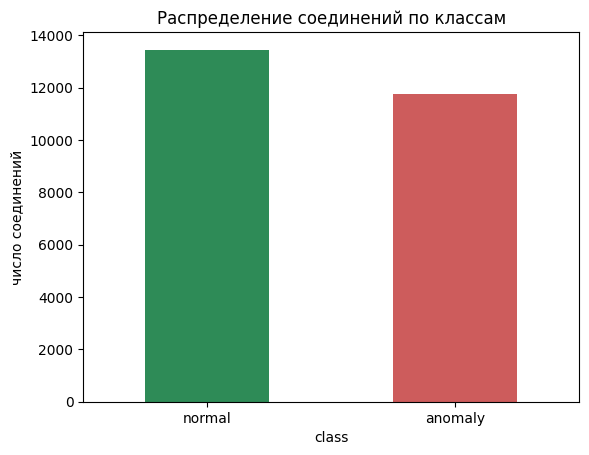

In [7]:
# Распределение по классам
counts = df['class'].value_counts()
print(counts)
print()
print('Доли: normal {:.1%}, anomaly {:.1%}'.format(counts['normal'] / len(df),
                                                 counts['anomaly'] / len(df)))
counts.plot.bar(color=['seagreen', 'indianred'])
plt.title('Распределение соединений по классам')
plt.ylabel('число соединений')
plt.xticks(rotation=0)
plt.show()

Классы почти сбалансированы (примерно 53 % / 47 %) — это приятное отличие от реального трафика, где атаки составляют доли процента. Здесь accuracy ещё имеет смысл, но precision/recall по классу `anomaly` всё равно информативнее.

## Шаг 2. Предобработка данных + дискретизация по варианту

Три операции:

1. **Разделение на train/test** — 70 / 30, со стратификацией (`stratify=y`), чтобы пропорция классов сохранилась в обеих частях.
2. **Кодирование категориальных признаков** — `OrdinalEncoder` заменяет каждую строковую категорию её номером (алгоритмам sklearn нужны числа). Параметр `handle_unknown='use_encoded_value'` нужен на случай категории, которая встретится в тесте, но не встречалась в train (без него возникнет ошибка).
3. **Масштабирование числовых признаков** — `MinMaxScaler` приводит каждый признак к диапазону [0, 1]. Без этого признаки с большими значениями (например, `src_bytes` — десятки тысяч) «задавят» все остальные признаки.

Обе операции собраны в `ColumnTransformer` и встраиваются в **конвейер** (pipeline) вместе с классификатором. Важно: обучение преобразований (`fit`) происходит **только на тренировочной выборке** — нельзя смешивать данные для обучения и данные для тестирования.

In [30]:
X = df.drop(columns=['class'])
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=RANDOM_STATE, stratify=y)

print(f'train: {X_train.shape[0]} соединений, test: {X_test.shape[0]} соединений')
print('Доля anomaly: train {:.1%}, test {:.1%}'.format(
    (y_train == 'anomaly').mean(), (y_test == 'anomaly').mean()))

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
print('Категориальные:', cat_cols)
print('Числовые:', len(num_cols), 'признаков')

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

example = pd.DataFrame(preprocess.fit_transform(X_train), columns=cat_cols + num_cols)
example.head(3)

# ВАРИАНТ 40: дискретизация duration, src_bytes, dst_bytes по квантилям
BIN_COLS = ['duration', 'src_bytes', 'dst_bytes']

X_train_disc = X_train.copy()
X_test_disc = X_test.copy()

for col in BIN_COLS:
    bins = pd.qcut(X_train[col], q=5, duplicates='drop', retbins=True)[1]
    bins[0] = -np.inf
    bins[-1] = np.inf
    X_train_disc[col] = pd.cut(X_train[col], bins=bins, labels=False)
    X_test_disc[col] = pd.cut(X_test[col], bins=bins, labels=False)

cat_cols_disc = cat_cols + BIN_COLS
num_cols_disc = [c for c in num_cols if c not in BIN_COLS]

preprocess_disc = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols_disc),
    ('num', MinMaxScaler(), num_cols_disc),
])

train: 17634 соединений, test: 7558 соединений
Доля anomaly: train 46.6%, test 46.6%
Категориальные: ['protocol_type', 'service', 'flag']
Числовые: 36 признаков


## Шаг 3. Решающее дерево

Дерево решений последовательно делит данные по признакам (критерий — неоднородность Джини). Главный гиперпараметр — **максимальная глубина** `max_depth`: слишком мелкое дерево недообучается, слишком глубокое — запоминает шум (переобучение).

Подберём глубину перебором по сетке с кросс-валидацией (GridSearchCV): тренировочная выборка делится на 5 частей, каждая по очереди становится валидационной, оценка усредняется. Тестовая выборка в подборе не участвует. Подбор выполним для двух моделей по одной схеме — базового дерева (непрерывные duration, src_bytes, dst_bytes) и дерева на их квантильных корзинах (Вариант 40, pd.qcut, q=5, duplicates='drop'), — чтобы сравнить accuracy и оценить эффект дискретизации.

In [15]:
# Базовое дерево (как было)
grid_tree = GridSearchCV(
    make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {'decisiontreeclassifier__max_depth': [3, 5, 7, 10, 15, 20, None]},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_tree.fit(X_train, y_train)
print(f'[База] Подбор по сетке: {time.time() - t0:.1f} с')
print('[База] Лучшие параметры:', grid_tree.best_params_)
print(f'[База] Accuracy на кросс-валидации: {grid_tree.best_score_:.4f}')

# Дерево на дискретизированных признаках (Вариант 40)
grid_tree_disc = GridSearchCV(
    make_pipeline(preprocess_disc, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {'decisiontreeclassifier__max_depth': [3, 5, 7, 10, 15, 20, None]},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_tree_disc.fit(X_train_disc, y_train)
print(f'[Дискр.] Подбор по сетке: {time.time() - t0:.1f} с')
print('[Дискр.] Лучшие параметры:', grid_tree_disc.best_params_)
print(f'[Дискр.] Accuracy на кросс-валидации: {grid_tree_disc.best_score_:.4f}')

[База] Подбор по сетке: 7.0 с
[База] Лучшие параметры: {'decisiontreeclassifier__max_depth': 15}
[База] Accuracy на кросс-валидации: 0.9946
[Дискр.] Подбор по сетке: 3.5 с
[Дискр.] Лучшие параметры: {'decisiontreeclassifier__max_depth': 20}
[Дискр.] Accuracy на кросс-валидации: 0.9933


[База] Accuracy на test: 0.996

              precision    recall  f1-score   support

     anomaly      0.995     0.995     0.995      3523
      normal      0.996     0.996     0.996      4035

    accuracy                          0.996      7558
   macro avg      0.995     0.995     0.995      7558
weighted avg      0.996     0.996     0.996      7558

[Дискр.] Accuracy на test: 0.994

              precision    recall  f1-score   support

     anomaly      0.996     0.992     0.994      3523
      normal      0.993     0.996     0.995      4035

    accuracy                          0.994      7558
   macro avg      0.995     0.994     0.994      7558
weighted avg      0.994     0.994     0.994      7558



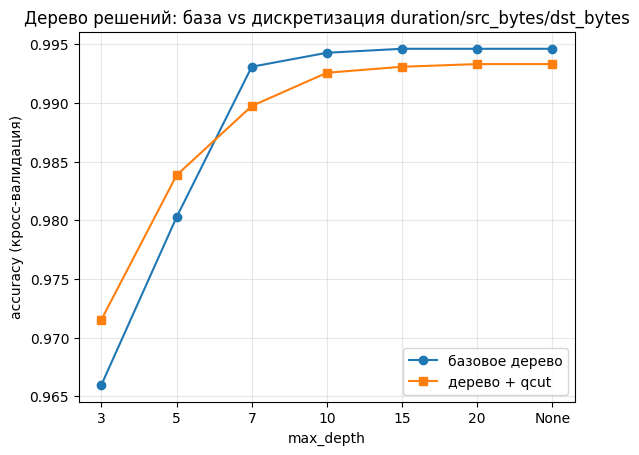

In [31]:
# Базовое дерево — метрики на test
model_tree = grid_tree.best_estimator_
y_pred = model_tree.predict(X_test)
print(f'[База] Accuracy на test: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3))

# Дерево на дискретизированных признаках — метрики на test
model_tree_disc = grid_tree_disc.best_estimator_
y_pred_disc = model_tree_disc.predict(X_test_disc)
print(f'[Дискр.] Accuracy на test: {accuracy_score(y_test, y_pred_disc):.3f}')
print()
print(classification_report(y_test, y_pred_disc, digits=3))

# График: две кривые на одном полотне
depths = [str(p['decisiontreeclassifier__max_depth']) for p in grid_tree.cv_results_['params']]
plt.plot(range(len(depths)), grid_tree.cv_results_['mean_test_score'],
         marker='o', label='базовое дерево')
plt.plot(range(len(depths)), grid_tree_disc.cv_results_['mean_test_score'],
         marker='s', label='дерево + qcut')
plt.xticks(range(len(depths)), depths)
plt.xlabel('max_depth')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('Дерево решений: база vs дискретизация duration/src_bytes/dst_bytes')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Шаг 4. Сравнение и выводы


In [32]:
models = {'Дерево решений': model_tree}

rows = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows[name] = [accuracy_score(y_test, y_pred),
                  precision_score(y_test, y_pred, pos_label='anomaly'),
                  recall_score(y_test, y_pred, pos_label='anomaly'),
                  f1_score(y_test, y_pred, pos_label='anomaly')]

summary = pd.DataFrame(rows, index=['Accuracy', 'Precision (anomaly)',
                                    'Recall (anomaly)', 'F1 (anomaly)']).T
print((summary * 100).round(2).astype(str) + '%')

               Accuracy Precision (anomaly) Recall (anomaly) F1 (anomaly)
Дерево решений   99.55%              99.52%           99.52%       99.52%


In [33]:
# Сравнение базового дерева и дерева на дискретизированных признаках
def _metrics(model, Xte, yte):
    yp = model.predict(Xte)
    return [accuracy_score(yte, yp),
            precision_score(yte, yp, pos_label='anomaly'),
            recall_score(yte, yp, pos_label='anomaly'),
            f1_score(yte, yp, pos_label='anomaly')]

cmp_tree = pd.DataFrame({
    'Дерево (базовое)':       _metrics(model_tree,      X_test,      y_test),
    'Дерево (дискретизация)': _metrics(model_tree_disc, X_test_disc, y_test),
}, index=['Accuracy', 'Precision (anomaly)', 'Recall (anomaly)', 'F1 (anomaly)']).T

print((cmp_tree * 100).round(2).astype(str) + '%')

                       Accuracy Precision (anomaly) Recall (anomaly)  \
Дерево (базовое)         99.55%              99.52%           99.52%   
Дерево (дискретизация)   99.44%              99.57%           99.23%   

                       F1 (anomaly)  
Дерево (базовое)             99.52%  
Дерево (дискретизация)        99.4%  


#Выводы
Три непрерывных признака (duration, src_bytes, dst_bytes)  заменили 5 квантильными корзинами через pd.qcut(..., q=5, duplicates='drop'). Границы корзин вычислялись только по тренировочной выборке и затем применялись к тестовой через pd.cut с теми же границами. После дискретизации эти признаки перенесены из числовых в категориальные и закодированы OrdinalEncoder.
Accuracy изменилась на 0.11% .


Дискретизация не помогла — accuracy и F1 слегка снизились. Precision по anomaly немного вырос (+0.05% ), но recall упал (−0.29%), т.е. модель стала осторожнее в предсказании атак — меньше ложных срабатываний, но больше пропущенных аномалий. Для системы обнаружения вторжений это нежелательный обмен: пропущенная атака (false negative) дороже ложной тревоги, поэтому падение recall при практически неизменной accuracy говорит в пользу базового дерева.

**Когда дискретизация полезна:**
- при сильном шуме/выбросах в непрерывных признаках;
- для моделей, не умеющих работать с непрерывными признаками;
- когда нужна интерпретируемость правил;
- при нелинейной ступенчатой зависимости между признаком и целевой переменной.